In [1]:
pip install mne numpy matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 51.5 MB/s eta 0:00:00


In [4]:
pip install mne-connectivity


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.2/115.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.1 MB/s eta 0:00:00


In [5]:
import mne
from mne_connectivity import spectral_connectivity_epochs
import matplotlib.pyplot as plt
import numpy as np


In [7]:
from google.colab import drive
drive.mount('/content/drive')
edf_path = '/content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf'
raw = mne.io.read_raw_edf(edf_path, preload=True)
raw.pick_types(eeg=True)  # Only EEG channels

# View basic info
print(raw.info)
raw.filter(1., 40., fir_design='firwin')  # Band-pass filter

Mounted at /content/drive
Extracting EDF parameters from /content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 183599  =      0.000 ...   367.198 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
<Info | 8 non-empty values
 bads: []
 ch_names: Trig, Fp1-LE, Fp2-LE, F3-LE, F4-LE, C3-LE, C4-LE, P3-LE, P4-LE, ...
 chs: 20 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: 2025-02-25 22:59:29 UTC
 nchan: 20
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: Azam>
>
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower t

<RawEDF | SUB_01.edf, 20 x 183600 (367.2 s), ~28.0 MiB, data loaded>

In [8]:

# ------------------- Create Epochs -------------------
events = mne.make_fixed_length_events(raw, duration=2.0)  # Use fixed 2s windows
epochs = mne.Epochs(raw, events, tmin=0, tmax=2.0, baseline=None, preload=True)


Not setting metadata
183 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 183 events and 1001 original time points ...
0 bad epochs dropped


In [11]:

# ------------------- Compute Connectivity -------------------
# Compute spectral connectivity (returns one object, not a tuple)
con = spectral_connectivity_epochs(
    data=epochs,
    method='coh',
    mode='multitaper',
    sfreq=raw.info['sfreq'],
    fmin=8., fmax=13.,  # Alpha band
    faverage=True,
    tmin=0.0, tmax=2.0,
    verbose=True
)

# Extract the connectivity matrix
con_matrix = con.get_data(output='dense')[:, :, 0]  # (n_channels, n_channels)

# Get channel names
ch_names = con.names


Replacing existing metadata with 3 columns
Connectivity computation...
only using indices for lower-triangular matrix
    computing connectivity for 190 connections
    using t=0.000s..2.000s for estimation (1001 points)
    frequencies: 8.5Hz..13.0Hz (10 points)
    connectivity scores will be averaged for each band
    Using multitaper spectrum estimation with 7 DPSS windows
    the following metrics will be computed: Coherence
    computing cross-spectral density for epoch 1
    computing cross-spectral density for epoch 2
    computing cross-spectral density for epoch 3
    computing cross-spectral density for epoch 4
    computing cross-spectral density for epoch 5
    computing cross-spectral density for epoch 6
    computing cross-spectral density for epoch 7
    computing cross-spectral density for epoch 8
    computing cross-spectral density for epoch 9
    computing cross-spectral density for epoch 10
    computing cross-spectral density for epoch 11
    computing cross-spect

/usr/local/lib/python3.11/dist-packages/mne_connectivity/spectral/epochs_bivariate.py:81: RuntimeWarning: invalid value encountered in divide
  self.con_scores[con_idx] = np.abs(csd_mean) / np.sqrt(psd_xx * psd_yy)


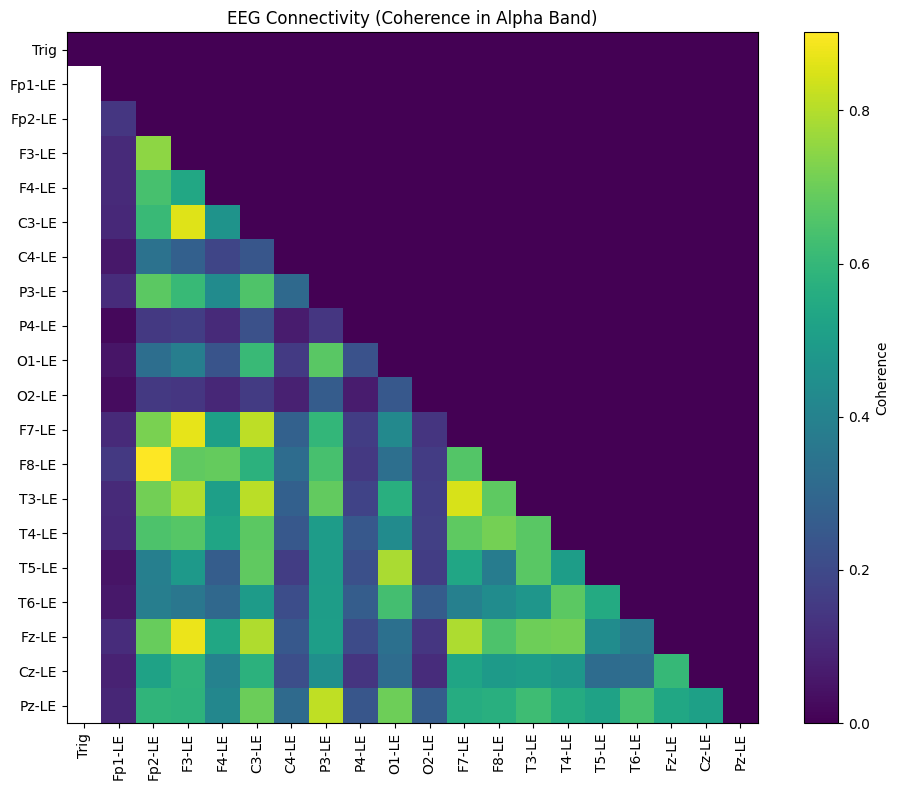

In [12]:

# Plotting
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))
im = plt.imshow(con_matrix, interpolation='nearest', cmap='viridis')
plt.title('EEG Connectivity (Coherence in Alpha Band)')
plt.colorbar(im, label='Coherence')
plt.xticks(np.arange(len(ch_names)), labels=ch_names, rotation=90)
plt.yticks(np.arange(len(ch_names)), labels=ch_names)
plt.tight_layout()
plt.show()



Computing coh...


/usr/local/lib/python3.11/dist-packages/mne_connectivity/spectral/epochs_bivariate.py:81: RuntimeWarning: invalid value encountered in divide
  self.con_scores[con_idx] = np.abs(csd_mean) / np.sqrt(psd_xx * psd_yy)


Computing imcoh...


/usr/local/lib/python3.11/dist-packages/mne_connectivity/spectral/epochs_bivariate.py:107: RuntimeWarning: invalid value encountered in divide
  self.con_scores[con_idx] = np.imag(csd_mean) / np.sqrt(psd_xx * psd_yy)


Computing pli...
Computing wpli...
Computing plv...


/usr/local/lib/python3.11/dist-packages/mne_connectivity/spectral/epochs_bivariate.py:124: RuntimeWarning: invalid value encountered in divide
  self._acc[con_idx] += csd_xy / np.abs(csd_xy)
/tmp/ipython-input-13-3302984606.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


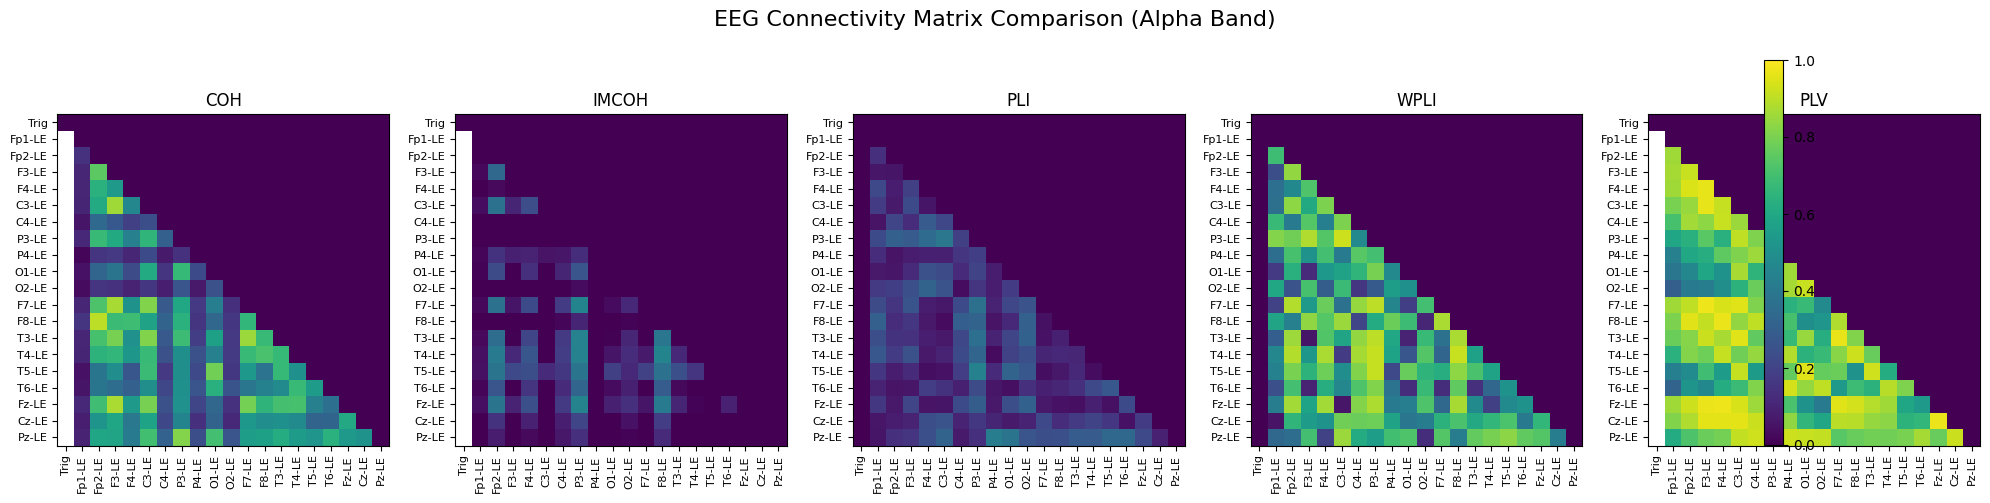

In [13]:
import mne
from mne_connectivity import spectral_connectivity_epochs
import matplotlib.pyplot as plt
import numpy as np

# Define methods to compare
methods = ['coh', 'imcoh', 'pli', 'wpli', 'plv']
method_matrices = {}
ch_names = epochs.info['ch_names']

# Compute connectivity matrices for each method
for method in methods:
    print(f"Computing {method}...")
    con = spectral_connectivity_epochs(
        data=epochs,
        method=method,
        mode='multitaper',
        sfreq=epochs.info['sfreq'],
        fmin=8., fmax=13.,
        faverage=True,
        tmin=0.0, tmax=2.0,
        verbose=False
    )
    con_matrix = con.get_data(output='dense')[:, :, 0]  # Remove frequency dim
    method_matrices[method] = con_matrix

# ------------------- Plot Comparison -------------------
fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 5))
if len(methods) == 1:
    axes = [axes]

for i, method in enumerate(methods):
    ax = axes[i]
    im = ax.imshow(method_matrices[method], cmap='viridis', vmin=0, vmax=1)
    ax.set_title(method.upper())
    ax.set_xticks(np.arange(len(ch_names)))
    ax.set_xticklabels(ch_names, rotation=90, fontsize=8)
    ax.set_yticks(np.arange(len(ch_names)))
    ax.set_yticklabels(ch_names, fontsize=8)

fig.suptitle("EEG Connectivity Matrix Comparison (Alpha Band)", fontsize=16)
fig.colorbar(im, ax=axes, orientation='vertical', fraction=0.02)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
